# 04: Reentry forecaster
Labels: SATCAT decay date (day precision). Time-ordered split: 60% train, 20% conformal calibration, newest 20% holdout. Training rows must have decayed before the block they are evaluated against.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})
ROOT = Path.cwd().parent
W = ROOT / "warehouse_repo" / "warehouse"
B = ROOT / "build_out"
from kessler.warehouse.db import connect
con = connect(W)

In [2]:
bt=json.load(open(B/'site/reentry/backtest.json')); pd.DataFrame(bt['metrics'])

,model,mae_days,mae_pct,coverage80,median_lead_days,skill_vs_baseline
0,Quantile GBM + conformal,2.847144,52.370465,0.839350,69.843514,0.904935
1,Quantile GBM (raw),2.847144,52.370465,0.626354,69.843514,0.904935
2,Physics baseline,29.949468,362.862715,0.140794,0.000000,0.000000


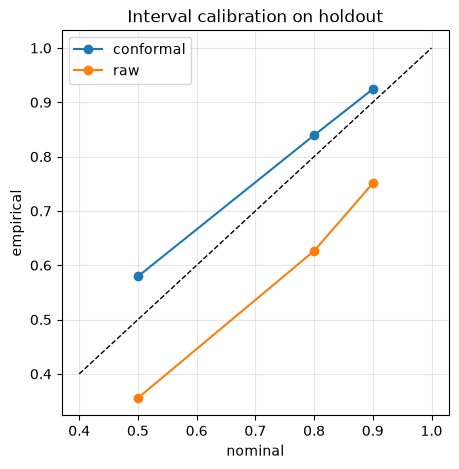

In [3]:
cal=pd.DataFrame(bt['calibration'])
fig,ax=plt.subplots(figsize=(5,5)); ax.plot([0.4,1],[0.4,1],'k--',lw=1)
for k,g in cal.groupby('model'): ax.plot(g.nominal,g.empirical,'o-',label=k)
ax.set_xlabel('nominal'); ax.set_ylabel('empirical'); ax.legend(); ax.set_title('Interval calibration on holdout');

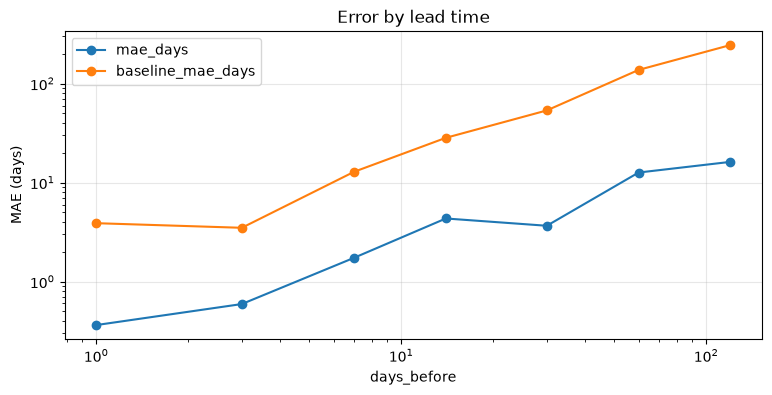

In [4]:
lt=pd.DataFrame(bt['lead_time'])
ax=lt.plot(x='days_before',y=['mae_days','baseline_mae_days'],logx=True,logy=True,marker='o'); ax.set_ylabel('MAE (days)'); ax.set_title('Error by lead time');

In [5]:
pd.DataFrame(json.load(open(B/'site/reentry/forecasts.json'))).head(15)[['name','norad','object_type','perigee_km','p10','p50','p90']]

,name,norad,object_type,perigee_km,p10,p50,p90
0,OBJECT D,43834,UNK,238.1,2026-10-20T21:59:48.371122147+00:00,2026-10-21T13:58:47.971912794+00:00,2026-10-24T05:08:38.495640727+00:00
1,COSMOS 1408 DEB,50058,DEB,240.1,2026-10-20T22:34:14.254486602+00:00,2026-10-24T01:50:18.831393381+00:00,2026-10-29T16:33:02.705544552+00:00
2,NOAA 17 DEB,48737,DEB,353.1,2026-10-24T16:18:02.602585255+00:00,2026-10-26T02:55:14.486004750+00:00,2026-10-28T21:06:18.030101518+00:00
3,CZ-6A DEB,54346,DEB,318.0,2026-10-24T15:34:04.560107767+00:00,2026-10-26T21:45:03.578283397+00:00,2026-10-28T22:16:54.986031370+00:00
4,CZ-2C R/B,54039,R/B,288.6,2026-10-24T06:30:05.811943144+00:00,2026-10-31T03:42:53.214997890+00:00,2026-11-17T06:48:43.402034810+00:00
5,FENGYUN 1C DEB,30744,DEB,387.7,2026-10-28T00:56:23.788836718+00:00,2026-10-31T10:31:01.434649039+00:00,2026-11-08T21:12:46.059468408+00:00
6,COSMOS 2251 DEB,33821,DEB,403.1,2026-10-21T08:34:28.656527816+00:00,2026-11-01T23:48:14.657837892+00:00,2027-01-03T06:15:07.203333942+00:00
7,COSMOS 2251 DEB,35602,DEB,376.3,2026-10-22T05:21:13.171785799+00:00,2026-11-05T16:42:54.611680944+00:00,2027-01-09T07:01:34.237318056+00:00
8,CZ-6C R/B,100472,R/B,396.5,2026-10-23T08:12:14.740595208+00:00,2026-11-15T12:41:54.757359147+00:00,2026-12-22T16:17:39.027435930+00:00
9,COSMOS 2251 DEB,33818,DEB,371.7,2026-11-01T21:13:01.015677465+00:00,2026-11-17T05:58:44.314649457+00:00,2026-12-04T10:08:12.021962127+00:00
